# Lab 8: Artificial Neural Networks (ANN)

> Add blockquote


**CS106: Basics of Machine Learning & Applications**  
**Department of Computer Science & Engineering, Delhi Technological University**

## Aim
To train, inspect and evaluate artificial neural networks using `MLPClassifier` and `MLPRegressor`, and compare them with logistic regression, linear regression and KNN.

## Datasets
- **Q1:** Wisconsin Breast Cancer — `sklearn.datasets.load_breast_cancer()`
- **Q2:** Two Moons — `sklearn.datasets.make_moons(n_samples=400, noise=0.30, random_state=7)`
- **Q3:** Diabetes — `sklearn.datasets.load_diabetes()`

No CSV files or downloads are required. Run cells from top to bottom. Numerical results can vary slightly across scikit-learn versions.

## Imports

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, make_moons, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score, r2_score, mean_absolute_error)

RANDOM_STATE = 7
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.set_printoptions(precision=4, suppress=True)
print("Imports complete.")

Imports complete.


# Q1. Breast cancer classification

(a) Dataset, labels, descriptive statistics and feature scales

Dataset shape (rows, columns including target): (569, 31)
\nClass distribution:
target
malignant (0)    212
benign (1)       357
Name: count, dtype: int64
\nLabel mapping: {0: np.str_('malignant'), 1: np.str_('benign')}
\nDescriptive statistics for five features:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
count,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360
std,3.524049,4.301036,24.298981,351.914129,0.014064
min,6.981000,9.710000,43.790000,143.500000,0.052630
25%,11.700000,16.170000,75.170000,420.300000,0.086370
50%,13.370000,18.840000,86.240000,551.100000,0.095870
75%,15.780000,21.800000,104.100000,782.700000,0.105300
max,28.110000,39.280000,188.500000,2501.000000,0.163400


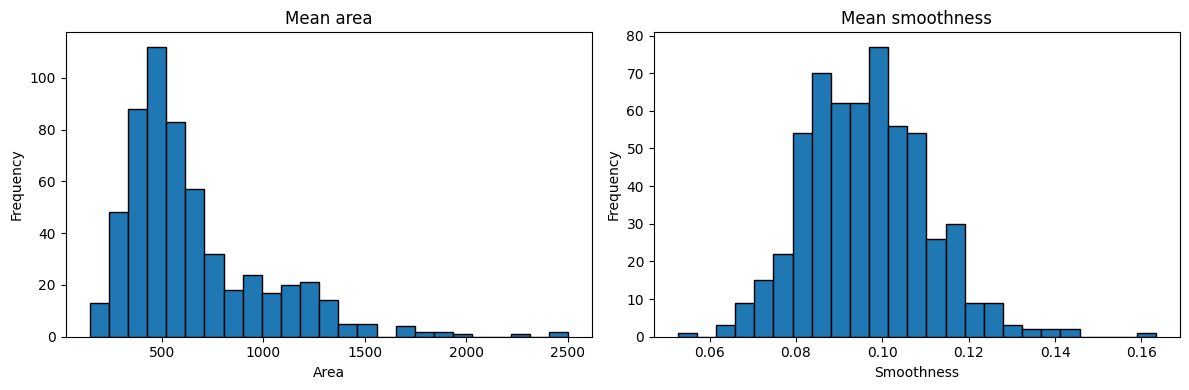

In [2]:
cancer = load_breast_cancer()
df_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df_cancer["target"] = cancer.target

print("Dataset shape (rows, columns including target):", df_cancer.shape)
print("\\nClass distribution:")
print(df_cancer["target"].value_counts().sort_index().rename(
    index={0: "malignant (0)", 1: "benign (1)"}))
print("\\nLabel mapping:", dict(enumerate(cancer.target_names)))
print("\\nDescriptive statistics for five features:")
display(df_cancer[list(cancer.feature_names[:5])].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_cancer["mean area"], bins=25, edgecolor="black")
ax[0].set(title="Mean area", xlabel="Area", ylabel="Frequency")
ax[1].hist(df_cancer["mean smoothness"], bins=25, edgecolor="black")
ax[1].set(title="Mean smoothness", xlabel="Smoothness", ylabel="Frequency")
plt.tight_layout()
plt.show()

Prediction before modelling: Mean area has values in the hundreds or thousands, while mean smoothness is a small decimal. Without scaling, large-magnitude inputs can dominate the optimisation and make training less stable. Standardisation should put features on comparable scales and usually improve ANN training.

(b)(i) One neuron — manual calculation and NumPy verification

In [3]:
x = np.array([2.0, 3.0])
w = np.array([0.5, -1.0])
b = 0.5
z = w @ x + b
sigmoid_z = 1 / (1 + np.exp(-z))
relu_z = max(0, z)
print("z =", z)
print("sigmoid(z) =", round(float(sigmoid_z), 4))
print("ReLU(z) =", relu_z)

z = -1.5
sigmoid(z) = 0.1824
ReLU(z) = 0


### Manual Calculation

**1. Weighted Sum (z)**

z = (0.5 × 2) + (-1 × 3) + 0.5

z = 1 - 3 + 0.5 = -1.5

**2. Sigmoid Activation**

σ(z) = 1 / (1 + e^(-z))

σ(-1.5) = 1 / (1 + e^(1.5))

σ(-1.5) ≈ 0.1824

**3. ReLU Activation**

ReLU(z) = max(0, z)

ReLU(-1.5) = max(0, -1.5) = 0

**Conclusion:** The calculated values are:
- Weighted Sum (z) = -1.5
- Sigmoid Output = 0.1824
- ReLU Output = 0

These values are verified by the NumPy output.

**(b)(ii) Forward pass through a 2–3–1 network**

In [4]:
def sigmoid(v):
    return 1 / (1 + np.exp(-v))

def relu(v):
    return np.maximum(0, v)

X = np.array([[1.0, 4.0]])
W1 = np.array([[0.5, -1.0, 0.8],
               [0.3,  0.2, -0.5]])
b1 = np.array([0.1, 0.0, -0.2])
W2 = np.array([[1.0], [-1.5], [0.7]])
b2 = np.array([0.05])

z1 = X @ W1 + b1
hidden = relu(z1)
z2 = hidden @ W2 + b2
output = sigmoid(z2)
print("Hidden pre-activations:", z1)
print("Hidden activations after ReLU:", hidden)
print("Output pre-activation:", z2)
print("Output probability:", output)

Hidden pre-activations: [[ 1.8 -0.2 -1.4]]
Hidden activations after ReLU: [[1.8 0.  0. ]]
Output pre-activation: [[1.85]]
Output probability: [[0.8641]]


### Manual Calculation

**Input:** x = (1, 4)

**1. Hidden Layer Calculations**

Hidden Neuron 1:

z₁ = (1 × 0.5) + (4 × 0.3) + 0.1

z₁ = 0.5 + 1.2 + 0.1 = 1.8

Hidden Neuron 2:

z₂ = (1 × -1.0) + (4 × 0.2) + 0

z₂ = -1.0 + 0.8 = -0.2

Hidden Neuron 3:

z₃ = (1 × 0.8) + (4 × -0.5) - 0.2

z₃ = 0.8 - 2.0 - 0.2 = -1.4

**2. Apply ReLU Activation**

ReLU(z) = max(0, z)

Hidden Layer Output = [1.8, 0, 0]

**3. Output Layer Calculation**

Output Score:

z = (1.8 × 1) + (0 × -1.5) + (0 × 0.7) + 0.05

z = 1.8 + 0 + 0 + 0.05 = 1.85

**4. Apply Sigmoid Activation**

σ(z) = 1 / (1 + e^(-z))

σ(1.85) = 1 / (1 + e^(-1.85))

σ(1.85) ≈ 0.8641

**Conclusion:** The final output of the neural network is approximately **0.8641**.

**(c) Raw features versus StandardScaler**

In [5]:
X_c, y_c = cancer.data, cancer.target
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=0.25, random_state=RANDOM_STATE, stratify=y_c)

raw_mlp = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500,
                        random_state=RANDOM_STATE)
raw_mlp.fit(X_train_c, y_train_c)

scaled_mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500,
                  random_state=RANDOM_STATE))
scaled_mlp.fit(X_train_c, y_train_c)

q1c = pd.DataFrame([
    ["MLP without scaling", raw_mlp.score(X_train_c, y_train_c), raw_mlp.score(X_test_c, y_test_c)],
    ["StandardScaler + MLP", scaled_mlp.score(X_train_c, y_train_c), scaled_mlp.score(X_test_c, y_test_c)]
], columns=["Model", "Training accuracy", "Test accuracy"])
display(q1c.round(4))

,Model,Training accuracy,Test accuracy
0,MLP without scaling,0.9014,0.9091
1,StandardScaler + MLP,0.9930,0.9860


Explanation: Scaling makes the input dimensions comparable. It generally improves optimisation because gradient-based training no longer has to handle features with vastly different magnitudes. The exact measured difference is shown above.

**(d) Loss curve, iteration count and convergence warning**

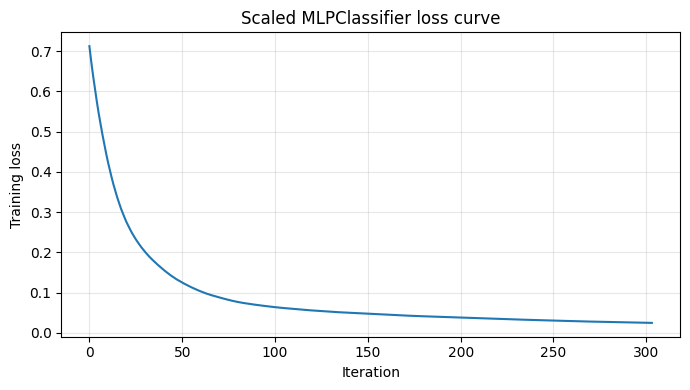

n_iter_ = 304
Test accuracy with max_iter=20: 0.9301


In [6]:
fitted_mlp = scaled_mlp.named_steps["mlpclassifier"]
plt.figure(figsize=(7, 4))
plt.plot(fitted_mlp.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Scaled MLPClassifier loss curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("n_iter_ =", fitted_mlp.n_iter_)

short_mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=20,
                  random_state=RANDOM_STATE))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    short_mlp.fit(X_train_c, y_train_c)
    for w in caught:
        print(type(w.message).__name__ + ":", str(w.message))
print("Test accuracy with max_iter=20:",
      round(accuracy_score(y_test_c, short_mlp.predict(X_test_c)), 4))

Explanation: max_iter=20 limits the optimiser to 20 training iterations. If it has not met its stopping criterion by then, scikit-learn raises a ConvergenceWarning. The fit may stop before the loss has stabilised, so its predictions can be worse or less reliable than a converged fit. The warning does not mean that the code crashed.

**(e) Parameter shapes and count**

In [7]:
ann = fitted_mlp
print("coefs_ shapes:", [a.shape for a in ann.coefs_])
print("intercepts_ shapes:", [a.shape for a in ann.intercepts_])
parameter_count = sum(a.size for a in ann.coefs_) + sum(a.size for a in ann.intercepts_)
manual_count = (30*16 + 16) + (16*8 + 8) + (8*1 + 1)
print("Parameter count from fitted model:", parameter_count)
print("Manual parameter count:", manual_count)
print("Logistic regression parameters (30 coefficients + intercept):", 31)

coefs_ shapes: [(30, 16), (16, 8), (8, 1)]
intercepts_ shapes: [(16,), (8,), (1,)]
Parameter count from fitted model: 641
Manual parameter count: 641
Logistic regression parameters (30 coefficients + intercept): 31


### Model Parameter Comparison

**1. Artificial Neural Network (ANN)**

Layer 1:
Parameters = (30 × 16) + 16 = 496

Layer 2:
Parameters = (16 × 8) + 8 = 136

Output Layer:
Parameters = (8 × 1) + 1 = 9

Total Parameters = 496 + 136 + 9 = **641**

**2. Logistic Regression**

- Number of input features = 30
- Coefficients = 30
- Intercept = 1

Total Parameters = 30 + 1 = **31**

**3. Comparison and Observation**

The ANN has 641 parameters, whereas Logistic Regression has only 31 parameters.

- ANN can learn complex, nonlinear patterns due to its multiple layers and activation functions.
- However, having many parameters relative to a small dataset increases the risk of overfitting.
- Logistic Regression is simpler, easier to interpret, and generally less prone to overfitting with limited data.

**Conclusion:** Although ANN offers greater flexibility in learning complex patterns, Logistic Regression may generalize better on smaller datasets due to its simpler structure.

**(f) Confusion matrix, metrics and threshold trade-off**

In [8]:
y_pred_c = scaled_mlp.predict(X_test_c)
print("Confusion matrix (rows=true [malignant, benign], columns=predicted [malignant, benign]):")
print(confusion_matrix(y_test_c, y_pred_c, labels=[0, 1]))
print(classification_report(y_test_c, y_pred_c, labels=[0, 1],
                            target_names=["malignant", "benign"], digits=4,
                            zero_division=0))

probabilities = scaled_mlp.predict_proba(X_test_c)
malignant_column = list(scaled_mlp.classes_).index(0)
p_malignant = probabilities[:, malignant_column]
actual_malignant = (y_test_c == 0)
threshold_results = []
for threshold in [0.5, 0.3, 0.1]:
    predicted_malignant = p_malignant >= threshold
    fn = int(np.sum(actual_malignant & ~predicted_malignant))
    fp = int(np.sum(~actual_malignant & predicted_malignant))
    threshold_results.append([threshold, fn, fp])
display(pd.DataFrame(threshold_results, columns=[
    "Malignant probability threshold", "False negatives", "False positives"]))

Confusion matrix (rows=true [malignant, benign], columns=predicted [malignant, benign]):
[[52  1]
 [ 1 89]]
              precision    recall  f1-score   support

   malignant     0.9811    0.9811    0.9811        53
      benign     0.9889    0.9889    0.9889        90

    accuracy                         0.9860       143
   macro avg     0.9850    0.9850    0.9850       143
weighted avg     0.9860    0.9860    0.9860       143



,Malignant probability threshold,False negatives,False positives
0,0.5,1,1
1,0.3,1,2
2,0.1,0,5


In cancer screening, a false negative is generally more costly: a malignant case is classified as benign and may be missed or have treatment delayed. Lowering the malignant-probability threshold flags more cases as malignant. This usually reduces false negatives but increases false positives, leading to more follow-up tests for people who are actually benign. The table quantifies the trade-off for this test split.

**(g) ANN, Logistic Regression and KNN comparison**

In [9]:
models_c = {
    "ANN (16, 8)": make_pipeline(StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500, random_state=RANDOM_STATE)),
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}
comparison = []
for name, model in models_c.items():
    start = time.perf_counter()
    model.fit(X_train_c, y_train_c)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    pred = model.predict(X_test_c)
    predict_seconds = time.perf_counter() - start
    comparison.append([name, accuracy_score(y_test_c, pred), fit_seconds, predict_seconds])
display(pd.DataFrame(comparison, columns=[
    "Model", "Test accuracy", "Fit time (s)", "Predict time (s)"]).round(6))

,Model,Test accuracy,Fit time (s),Predict time (s)
0,"ANN (16, 8)",0.986014,0.657509,0.001287
1,Logistic Regression,0.979021,0.085349,0.001150
2,KNN (k=5),0.972028,0.006646,0.094620


ANN and logistic regression are eager learners: they learn model parameters during fitting, so fitting can take longer but prediction is relatively direct. KNN is a lazy learner: fitting mainly stores the examples, while prediction computes distances to stored training points. Consequently KNN often fits quickly but can take longer to predict. Timings are machine-dependent.

# **Q2. Two-moons classification**

**Setup and (a) data plot plus Logistic Regression baseline**

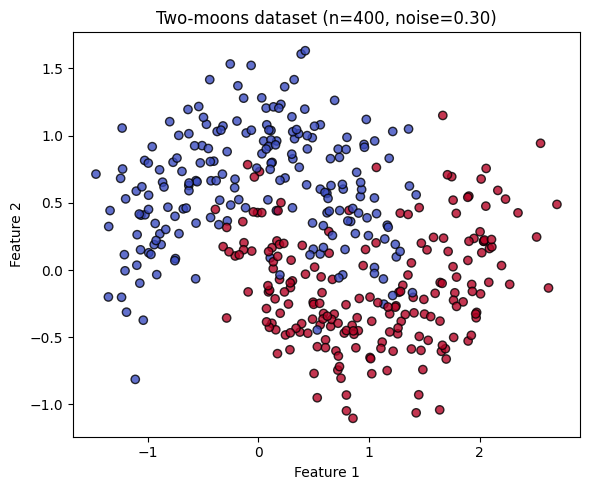

Logistic Regression training accuracy: 0.8567
Logistic Regression test accuracy: 0.83


In [10]:
X_m, y_m = make_moons(n_samples=400, noise=0.30, random_state=7)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_m, y_m, test_size=0.25, random_state=7, stratify=y_m)

plt.figure(figsize=(6, 5))
plt.scatter(X_m[:, 0], X_m[:, 1], c=y_m, cmap="coolwarm",
            edgecolor="black", alpha=0.8)
plt.title("Two-moons dataset (n=400, noise=0.30)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

moon_lr = LogisticRegression(random_state=7)
moon_lr.fit(X_train_m, y_train_m)
print("Logistic Regression training accuracy:", round(moon_lr.score(X_train_m, y_train_m), 4))
print("Logistic Regression test accuracy:", round(moon_lr.score(X_test_m, y_test_m), 4))

Logistic regression learns a linear decision boundary (a straight line in this two-dimensional feature space). The two classes form interleaving curved moons, so a single straight line cannot follow their geometry and will misclassify some points.

**(b) Effect of hidden-layer architecture**

In [11]:
architectures = [(2,), (4,), (16,), (64,), (16, 8), (64, 64)]
architecture_rows = []
for hidden in architectures:
    model = MLPClassifier(hidden_layer_sizes=hidden, max_iter=3000, random_state=7)
    model.fit(X_train_m, y_train_m)
    train_acc = model.score(X_train_m, y_train_m)
    test_acc = model.score(X_test_m, y_test_m)
    architecture_rows.append([str(hidden), train_acc, test_acc, train_acc-test_acc])
display(pd.DataFrame(architecture_rows, columns=[
    "Hidden layers", "Training accuracy", "Test accuracy", "Train-test gap"]).round(4))

,Hidden layers,Training accuracy,Test accuracy,Train-test gap
0,"(2,)",0.8633,0.83,0.0333
1,"(4,)",0.8633,0.83,0.0333
2,"(16,)",0.8867,0.83,0.0567
3,"(64,)",0.9167,0.91,0.0067
4,"(16, 8)",0.9267,0.94,-0.0133
5,"(64, 64)",0.9233,0.95,-0.0267


Low training and test scores indicate underfitting. A high training score with a substantially lower test score indicates overfitting. Increasing network size increases the range of boundaries the model can represent; it does not guarantee better test performance, because extra flexibility can also fit noise.

**(c) Activation functions**

In [14]:
activation_rows = []
for activation in ["identity", "logistic", "tanh", "relu"]:
    model = MLPClassifier(hidden_layer_sizes=(16, 8), activation=activation,
                          max_iter=3000, random_state=7)
    model.fit(X_train_m, y_train_m)
    activation_rows.append([activation, model.score(X_train_m, y_train_m),
                            model.score(X_test_m, y_test_m)])
display(pd.DataFrame(activation_rows, columns=[
    "Activation", "Training accuracy", "Test accuracy"]).round(4))

,Activation,Training accuracy,Test accuracy
0,identity,0.8633,0.83
1,logistic,0.8633,0.83
2,tanh,0.8667,0.83
3,relu,0.9267,0.94


`identity` introduces no nonlinear transformation in the hidden layers. A composition of linear transformations is itself linear, so stacking such layers still produces an effectively linear decision function (with a logistic output for classification). It therefore behaves much like logistic regression and cannot represent the curved moon boundary. Logistic, tanh and ReLU introduce nonlinearity.

**(d) Decision boundaries**

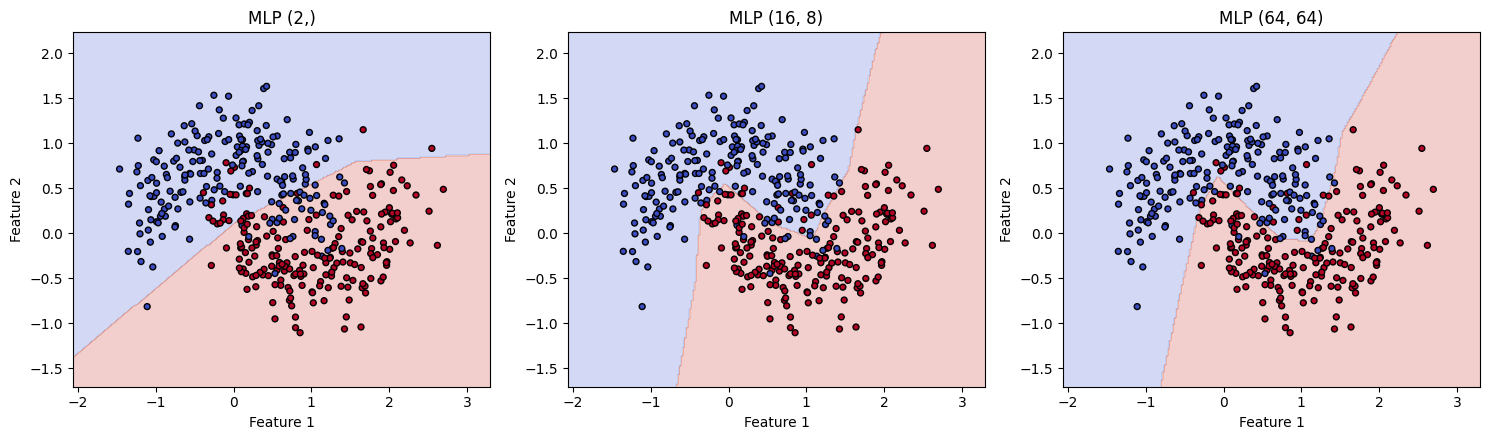

In [15]:
def draw_boundary(ax, model, X, y, title):
    x0_min, x0_max = X[:, 0].min()-0.6, X[:, 0].max()+0.6
    x1_min, x1_max = X[:, 1].min()-0.6, X[:, 1].max()+0.6
    xx, yy = np.meshgrid(np.linspace(x0_min, x0_max, 250),
                         np.linspace(x1_min, x1_max, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
               edgecolor="black", s=18)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, hidden in zip(axes, [(2,), (16, 8), (64, 64)]):
    model = MLPClassifier(hidden_layer_sizes=hidden, max_iter=3000, random_state=7)
    model.fit(X_train_m, y_train_m)
    draw_boundary(ax, model, X_m, y_m, f"MLP {hidden}")
plt.tight_layout()
plt.show()

A small network tends to create a simpler boundary; the (16, 8) network can form a more flexible curved boundary; and (64, 64) has still more capacity and may create unnecessarily intricate regions around noisy samples. KNN boundaries from Lab 7 are local and can be jagged because each prediction depends on nearby stored points. MLP boundaries are learned globally through weights.

**(e) L2 regularisation and early stopping**

In [16]:
settings = [
    ("alpha=0.0001", {"alpha": 0.0001}),
    ("alpha=0.01", {"alpha": 0.01}),
    ("alpha=1", {"alpha": 1}),
    ("alpha=10", {"alpha": 10}),
    ("early_stopping=True", {"alpha": 0.0001, "early_stopping": True})
]
regularisation_rows = []
for label, kwargs in settings:
    model = MLPClassifier(hidden_layer_sizes=(64, 64), max_iter=3000,
                           random_state=7, **kwargs)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(X_train_m, y_train_m)
    train_acc, test_acc = model.score(X_train_m, y_train_m), model.score(X_test_m, y_test_m)
    regularisation_rows.append([label, train_acc, test_acc, train_acc-test_acc, model.n_iter_])
display(pd.DataFrame(regularisation_rows, columns=[
    "Setting", "Training accuracy", "Test accuracy", "Train-test gap", "Iterations"]).round(4))

,Setting,Training accuracy,Test accuracy,Train-test gap,Iterations
0,alpha=0.0001,0.9233,0.95,-0.0267,280
1,alpha=0.01,0.9233,0.95,-0.0267,280
2,alpha=1,0.9167,0.90,0.0167,420
3,alpha=10,0.8500,0.82,0.0300,307
4,early_stopping=True,0.8400,0.79,0.0500,19


Larger alpha applies stronger L2 weight regularisation, discouraging large weights and reducing model flexibility. early_stopping=True holds out part of the training data for validation and stops training when validation performance stops improving. Both methods can reduce overfitting, although excessive regularisation can instead cause underfitting.

**(f) Random initialisation and cross-validation**

In [17]:
seed_rows = []
for seed in range(10):
    model = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=3000, random_state=seed)
    model.fit(X_train_m, y_train_m)
    seed_rows.append([seed, model.score(X_test_m, y_test_m)])
seed_df = pd.DataFrame(seed_rows, columns=["random_state", "Test accuracy"])
display(seed_df.round(4))
print("Mean test accuracy:", round(seed_df["Test accuracy"].mean(), 4))
print("Population standard deviation:", round(seed_df["Test accuracy"].std(ddof=0), 4))

cv_model = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=3000, random_state=7)
cv_scores = cross_val_score(cv_model, X_train_m, y_train_m, cv=5, scoring="accuracy")
print("5-fold CV scores:", np.round(cv_scores, 4))
print("Mean 5-fold CV accuracy:", round(cv_scores.mean(), 4))
print("CV standard deviation:", round(cv_scores.std(), 4))

,random_state,Test accuracy
0,0,0.92
1,1,0.92
2,2,0.94
3,3,0.93
4,4,0.94
5,5,0.93
6,6,0.93
7,7,0.94
8,8,0.93
9,9,0.92


Mean test accuracy: 0.93
Population standard deviation: 0.0077
5-fold CV scores: [0.95   0.9167 0.8667 0.8333 0.8833]
Mean 5-fold CV accuracy: 0.89
CV standard deviation: 0.0403


Different seeds produce different initial weights and can lead to different optimisation paths and fitted solutions. Comparing models from one random run can therefore be misleading. Repeated initialisations show sensitivity to the seed, while cross-validation measures performance across several training/validation splits of the training data.

**(g) GridSearchCV and KNN comparison**

In [18]:
mlp_pipe = make_pipeline(StandardScaler(),
    MLPClassifier(max_iter=3000, random_state=7))
param_grid = {
    "mlpclassifier__hidden_layer_sizes": [(16,), (16, 8), (32, 16)],
    "mlpclassifier__alpha": [0.0001, 0.01]
}
grid = GridSearchCV(mlp_pipe, param_grid, cv=5, scoring="accuracy",
                    n_jobs=-1, return_train_score=True)
grid.fit(X_train_m, y_train_m)

grid_table = pd.DataFrame(grid.cv_results_)[[
    "param_mlpclassifier__hidden_layer_sizes",
    "param_mlpclassifier__alpha", "mean_train_score",
    "mean_test_score", "std_test_score", "rank_test_score"
]].rename(columns={
    "param_mlpclassifier__hidden_layer_sizes": "Hidden layers",
    "param_mlpclassifier__alpha": "Alpha",
    "mean_train_score": "Mean training CV accuracy",
    "mean_test_score": "Mean validation accuracy",
    "std_test_score": "Validation std",
    "rank_test_score": "Rank"
})
display(grid_table.sort_values("Rank").round(4))
print("Best parameters:", grid.best_params_)
print("Best mean CV accuracy:", round(grid.best_score_, 4))

best_mlp = grid.best_estimator_
best_pred = best_mlp.predict(X_test_m)
print("Tuned MLP test accuracy:", round(accuracy_score(y_test_m, best_pred), 4))
print("Tuned MLP confusion matrix:")
print(confusion_matrix(y_test_m, best_pred))
print("Tuned MLP classification report:")
print(classification_report(y_test_m, best_pred, digits=4, zero_division=0))

knn_moon = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_moon.fit(X_train_m, y_train_m)
knn_pred = knn_moon.predict(X_test_m)
print("KNN (k=5) test accuracy:", round(accuracy_score(y_test_m, knn_pred), 4))
print("KNN confusion matrix:")
print(confusion_matrix(y_test_m, knn_pred))

,Hidden layers,Alpha,Mean training CV accuracy,Mean validation accuracy,Validation std,Rank
5,"(32, 16)",0.0100,0.9225,0.9167,0.0279,1
2,"(32, 16)",0.0001,0.9183,0.9133,0.0287,2
4,"(16, 8)",0.0100,0.9225,0.9000,0.0447,3
1,"(16, 8)",0.0001,0.9208,0.9000,0.0447,3
0,"(16,)",0.0001,0.9083,0.8967,0.0371,5
3,"(16,)",0.0100,0.9000,0.8900,0.0389,6


Best parameters: {'mlpclassifier__alpha': 0.01, 'mlpclassifier__hidden_layer_sizes': (32, 16)}
Best mean CV accuracy: 0.9167
Tuned MLP test accuracy: 0.93
Tuned MLP confusion matrix:
[[47  3]
 [ 4 46]]
Tuned MLP classification report:
              precision    recall  f1-score   support

           0     0.9216    0.9400    0.9307        50
           1     0.9388    0.9200    0.9293        50

    accuracy                         0.9300       100
   macro avg     0.9302    0.9300    0.9300       100
weighted avg     0.9302    0.9300    0.9300       100

KNN (k=5) test accuracy: 0.9
KNN confusion matrix:
[[47  3]
 [ 7 43]]


Grid search selects hyperparameters using five-fold cross-validation on the training set only. The held-out test set is used once after selection, so it does not influence the choice. Compare the tuned MLP and KNN test scores and confusion matrices to see whether the additional ANN complexity gives a meaningful improvement on this split.

# **Q3. Diabetes regression**

**(a) Linear regression baseline**

In [19]:
diabetes = load_diabetes()
X_d, y_d = diabetes.data, diabetes.target
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_d, y_d, test_size=0.25, random_state=7)

linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train_d, y_train_d)
linear_pred_test = linear_model.predict(X_test_d)
print("Linear Regression test R²:", round(r2_score(y_test_d, linear_pred_test), 4))
print("Linear Regression test MAE:", round(mean_absolute_error(y_test_d, linear_pred_test), 4))

Linear Regression test R²: 0.5028
Linear Regression test MAE: 41.8684


**(b) MLPRegressor**

In [20]:
ann_reg = make_pipeline(StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=7))
with warnings.catch_warnings(record=True) as reg_warnings:
    warnings.simplefilter("always")
    ann_reg.fit(X_train_d, y_train_d)
    for w in reg_warnings:
        print(type(w.message).__name__ + ":", str(w.message))

pred_train_d = ann_reg.predict(X_train_d)
pred_test_d = ann_reg.predict(X_test_d)
print("ANN training R²:", round(r2_score(y_train_d, pred_train_d), 4))
print("ANN training MAE:", round(mean_absolute_error(y_train_d, pred_train_d), 4))
print("ANN test R²:", round(r2_score(y_test_d, pred_test_d), 4))
print("ANN test MAE:", round(mean_absolute_error(y_test_d, pred_test_d), 4))
print("Iterations:", ann_reg.named_steps["mlpregressor"].n_iter_)

ANN training R²: 0.7068
ANN training MAE: 32.6363
ANN test R²: 0.4225
ANN test MAE: 44.4154
Iterations: 2000


Compare training and test R²: a much higher training score than test score suggests overfitting. A convergence warning means the optimiser reached its iteration limit before satisfying its stopping criterion. The warning and the actual train/test scores should both be reported rather than assuming the model converged.

**(c) Smaller network, stronger alpha and early stopping**

In [21]:
regression_candidates = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "MLP (32,16), alpha=0.0001": make_pipeline(StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(32,16), alpha=0.0001,
                     max_iter=2000, random_state=7)),
    "MLP (8,), alpha=0.0001": make_pipeline(StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(8,), alpha=0.0001,
                     max_iter=3000, random_state=7)),
    "MLP (8,), alpha=0.1": make_pipeline(StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(8,), alpha=0.1,
                     max_iter=3000, random_state=7)),
    "MLP (8,), early stopping": make_pipeline(StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(8,), alpha=0.01,
                     early_stopping=True, max_iter=3000, random_state=7))
}
reg_rows, fitted_reg_models = [], {}
for name, model in regression_candidates.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(X_train_d, y_train_d)
    fitted_reg_models[name] = model
    p_train, p_test = model.predict(X_train_d), model.predict(X_test_d)
    reg_rows.append([name, r2_score(y_train_d, p_train),
                     r2_score(y_test_d, p_test),
                     mean_absolute_error(y_test_d, p_test)])
reg_results = pd.DataFrame(reg_rows, columns=[
    "Model", "Train R²", "Test R²", "Test MAE"]).sort_values("Test R²", ascending=False)
display(reg_results.round(4))
best_reg_name = reg_results.iloc[0]["Model"]
best_reg = fitted_reg_models[best_reg_name]
print("Best model in this comparison by test R²:", best_reg_name)

,Model,Train R²,Test R²,Test MAE
0,Linear Regression,0.5194,0.5028,41.8684
1,"MLP (32,16), alpha=0.0001",0.7068,0.4225,44.4154
3,"MLP (8,), alpha=0.1",0.5159,0.4123,45.8405
2,"MLP (8,), alpha=0.0001",0.5159,0.4123,45.8411
4,"MLP (8,), early stopping",0.4310,0.3500,49.0995


Best model in this comparison by test R²: Linear Regression


The diabetes dataset has only 442 observations and 10 input features. A neural network has substantially more flexibility than a linear model and may need more data to estimate its parameters reliably. If the linear baseline has the best test R² / MAE, the tested ANN configurations did not justify their extra complexity on this dataset. Use the measured table to make the conclusion.

**(d) Actual versus predicted values for the best model**

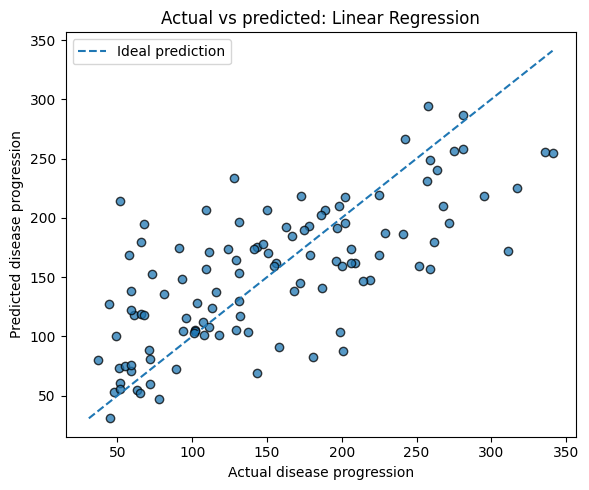

Points close to the diagonal are predicted more accurately; larger vertical deviations are larger errors.


In [22]:
best_test_pred = best_reg.predict(X_test_d)
plt.figure(figsize=(6, 5))
plt.scatter(y_test_d, best_test_pred, alpha=0.75, edgecolor="black")
lo = min(y_test_d.min(), best_test_pred.min())
hi = max(y_test_d.max(), best_test_pred.max())
plt.plot([lo, hi], [lo, hi], linestyle="--", label="Ideal prediction")
plt.xlabel("Actual disease progression")
plt.ylabel("Predicted disease progression")
plt.title("Actual vs predicted: " + best_reg_name)
plt.legend()
plt.tight_layout()
plt.show()
print("Points close to the diagonal are predicted more accurately; larger vertical deviations are larger errors.")

The model is most accurate for points close to the diagonal, where predicted and actual values are similar. Points well above or below the line indicate underprediction or overprediction. The scatter also shows whether predictions are concentrated around the mean and whether extreme target values are difficult to estimate.

**(e) Output activation**

A regression output must represent a broad range of real-valued targets, so it uses an unrestricted (identity/linear) output rather than sigmoid. A binary classifier uses sigmoid to map its final score to a value between 0 and 1, interpretable as a class probability.

# **Q4. Conclusion (4–5 lines)**

An ANN is preferable when the data contains nonlinear patterns that simpler models cannot capture, as the two-moons experiment demonstrates. Logistic or linear regression is often better when the relationship is approximately linear, data is limited, or interpretability and simplicity matter. KNN can model nonlinear boundaries and can be a strong baseline, but prediction may be slower because it compares new samples with stored training examples. ANNs require feature scaling and careful tuning, and can overfit or fail to converge. Choose an ANN when its validation/test performance improvement justifies the added complexity.